## Exploratory Data Analysis & Stylometric Feature Engineering: AI vs. Human Text Authorship

## Executive Summary & Objectives
This notebook presents a comprehensive Exploratory Data Analysis (EDA), linguistic and stylometric feature extraction pipeline, statistical feature evaluation, and dataset shift / semi-supervised readiness study for the **Cornell Tech CS 5785 Applied Machine Learning Kaggle Competition (*Human or AI?*)**.

### Dataset Overview
- **`train.csv`** ($N = 10,000$): Supervised training set with visible binary labels (`0` = Human, `1` = AI), balanced evenly at $5,000$ Human and $5,000$ AI passages.
- **`unlabeled.csv`** ($N = 3,000$): Unlabeled passages intended for semi-supervised learning and representation expansion.
- **`test.csv`** ($N = 3,000$): Held-out Kaggle evaluation passages (evaluated via Area Under the ROC Curve, **AUROC**).
- **`train_starter_2000.csv`** ($N = 2,000$): Stratified 2,000-row subset of `train.csv` ($1,000$ Human, $1,000$ AI) used to benchmark pipeline speed before full-scale execution (never merged with `train.csv`).

### Analysis Structure
1. **Schema & Data Integrity Check**: Column/type validation, missing value inspection, strict containment verification of `train_starter_2000.csv`, exact duplicate checks, and near-duplicate / data-leakage analysis across splits.
2. **Linguistic & Stylometric Feature Engineering**: Modular, fast extraction of **76 interpretable candidate features** across six linguistic families (Length & Structural, Lexical Diversity & Repetition, Punctuation & Formatting, Readability & Complexity, Syntactic & POS Patterns, and Discourse Markers & N-grams).
3. **Feature Evaluation & Statistical Analysis**: Parametric (Mean, SD, Welch's $t$-test, Point-Biserial $r_{pb}$) and non-parametric (Median, IQR, Mann-Whitney $U$, Mutual Information, 1D Linear vs. Non-Linear AUROC) evaluation, plus 5-fold cross-validated **LightGBM** and **Logistic Regression** baselines and collinearity clustering.
4. **Dataset Shift & Semi-Supervised Readiness**: Distributional comparison across `train.csv`, `unlabeled.csv`, and `test.csv`, domain/genre shift breakdown, and **Adversarial Validation** (`train` vs. `unlabeled` and `train` vs. `test`).
5. **Actionable Recommendations for Model Selection**: Feature pruning rules, structural artifact regularizers, semi-supervised learning protocols (`unlabeled.csv`), and domain-shift mitigation for `test.csv`.

In [1]:
import time
import re
import warnings
import numpy as np
import pandas as pd
from scipy.sparse import triu
from scipy.stats import mannwhitneyu, ttest_ind, pointbiserialr, ks_2samp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, display

warnings.filterwarnings('ignore')
sns.set_theme(
    style='whitegrid',
    palette='deep',
    font_scale=0.80,
    rc={
        'figure.dpi': 95,
        'savefig.dpi': 115,
        'font.size': 8.0,
        'axes.titlesize': 8.5,
        'axes.labelsize': 8.0,
        'xtick.labelsize': 7.5,
        'ytick.labelsize': 7.5,
        'legend.fontsize': 7.5,
        'figure.titlesize': 9.5,
    }
)
display(HTML(
    "<style>"
    ".jp-RenderedHTMLCommon, .rendered_html { font-size: 12.5px !important; line-height: 1.45 !important; }"
    ".jp-RenderedHTMLCommon table, .rendered_html table, table.dataframe { font-size: 11px !important; }"
    ".jp-RenderedHTMLCommon h1, .rendered_html h1 { font-size: 1.35em !important; }"
    ".jp-RenderedHTMLCommon h2, .rendered_html h2 { font-size: 1.18em !important; }"
    ".jp-RenderedHTMLCommon h3, .rendered_html h3 { font-size: 1.05em !important; }"
    ".jp-RenderedHTMLCommon h4, .rendered_html h4 { font-size: 0.98em !important; }"
    "</style>"
))
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print("Environment initialized successfully.")

Environment initialized successfully.


---
## 1. Schema & Data Integrity Check

We begin by loading all dataset files from `../data/` (with fallback to `data/`), inspecting schemas, data types, missing/null values, class balance, and verifying three critical integrity properties:
1. **Containment**: Whether `train_starter_2000.csv` is strictly a subset of `train.csv` across `(id, text, label)`.
2. **Exact Duplicates**: Whether exact or whitespace-normalized duplicate texts exist within or across splits.
3. **Near-Duplicate & Template Leakage**: Using character 3–5 gram and word 1–2 gram TF-IDF cosine similarity ($\ge 0.85$) across all $16,000$ passages to identify near-duplicate passages or shared structural templates.

In [2]:
from pathlib import Path

DATA_DIR = Path('../data') if Path('../data/train.csv').exists() else Path('data')

train_df = pd.read_csv(DATA_DIR / 'train.csv')
unlabeled_df = pd.read_csv(DATA_DIR / 'unlabeled.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
starter_df = pd.read_csv(DATA_DIR / 'train_starter_2000.csv')
sub_df = pd.read_csv(DATA_DIR / 'sample_submission.csv')

datasets = {
    'train.csv': train_df,
    'unlabeled.csv': unlabeled_df,
    'test.csv': test_df,
    'train_starter_2000.csv': starter_df,
    'sample_submission.csv': sub_df
}

schema_rows = []
for name, df in datasets.items():
    has_text = 'text' in df.columns
    wc = df['text'].str.split().str.len() if has_text else pd.Series(dtype=float)
    schema_rows.append({
        'Dataset': name,
        'Rows': len(df),
        'Columns': ', '.join(f"{c} ({dt})" for c, dt in zip(df.columns, df.dtypes)),
        'Null / Missing': int(df.isnull().sum().sum()),
        'Empty Strings': int((df['text'].str.strip() == '').sum()) if has_text else 0,
        'Label Balance (0 / 1)': f"{(df['label']==0).sum()} / {(df['label']==1).sum()}" if 'label' in df.columns and name != 'sample_submission.csv' else 'Hidden / N/A',
        'Word Count (Mean ± SD [Min, Max])': f"{wc.mean():.1f} ± {wc.std():.1f} [{wc.min()}, {wc.max()}]" if has_text else 'N/A'
    })

schema_summary = pd.DataFrame(schema_rows)
display(schema_summary)

,Dataset,Rows,Columns,Null / Missing,Empty Strings,Label Balance (0 / 1),"Word Count (Mean ± SD [Min, Max])"
0,train.csv,10000,"id (int64), text (object), label (int64)",0,0,5000 / 5000,"208.7 ± 62.7 [75, 350]"
1,unlabeled.csv,3000,"id (int64), text (object)",0,0,Hidden / N/A,"210.3 ± 65.5 [75, 350]"
2,test.csv,3000,"id (int64), text (object)",0,0,Hidden / N/A,"217.0 ± 61.0 [75, 350]"
3,train_starter_2000.csv,2000,"id (int64), text (object), label (int64)",0,0,1000 / 1000,"209.9 ± 62.7 [76, 349]"
4,sample_submission.csv,3000,"id (int64), label (float64)",0,0,Hidden / N/A,N/A


In [3]:
# 1. Verify strict containment of train_starter_2000.csv within train.csv
starter_merged = pd.merge(starter_df, train_df, on=['id', 'text', 'label'], how='inner')
print(f"[Containment Check] train_starter_2000 rows matching train.csv exactly on (id, text, label): {len(starter_merged)} / {len(starter_df)}")
assert len(starter_merged) == len(starter_df), "ERROR: train_starter_2000 is not strictly contained in train.csv!"

# 2. Check exact and whitespace-normalized duplicates within and across splits
def normalize_text(series):
    return series.str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)

norm_sets = {}
for name, df in [('train', train_df), ('unlabeled', unlabeled_df), ('test', test_df)]:
    exact_dup = df['text'].duplicated().sum()
    norm_s = normalize_text(df['text'])
    norm_dup = norm_s.duplicated().sum()
    norm_sets[name] = set(norm_s)
    print(f"[Duplicate Check] {name:10s}: exact duplicates = {exact_dup}, normalized duplicates = {norm_dup}")

print(f"[Cross-Split Exact/Normalized Overlap] train ∩ unlabeled = {len(norm_sets['train'] & norm_sets['unlabeled'])}, "
      f"train ∩ test = {len(norm_sets['train'] & norm_sets['test'])}, "
      f"unlabeled ∩ test = {len(norm_sets['unlabeled'] & norm_sets['test'])}")

# 3. Near-duplicate & structural template similarity check across all 16,000 passages
all_passages = pd.concat([
    train_df[['id', 'text', 'label']].assign(split='train'),
    unlabeled_df[['id', 'text']].assign(split='unlabeled', label=-1),
    test_df[['id', 'text']].assign(split='test', label=-1)
], ignore_index=True)

word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True)
X_word = word_vec.fit_transform(all_passages['text'])
sim_mat = triu(X_word @ X_word.T, k=1)
r_idx, c_idx = sim_mat.nonzero()
sim_vals = sim_mat.data

for thresh in [0.95, 0.90, 0.85, 0.80]:
    print(f"[Near-Duplicate Check] Word (1,2)-gram TF-IDF cosine similarity > {thresh:.2f}: {(sim_vals > thresh).sum()} pairs")

mask_85 = sim_vals > 0.85
pairs_85 = pd.DataFrame({
    'split_1': all_passages.loc[r_idx[mask_85], 'split'].values,
    'split_2': all_passages.loc[c_idx[mask_85], 'split'].values,
    'id_1': all_passages.loc[r_idx[mask_85], 'id'].values,
    'id_2': all_passages.loc[c_idx[mask_85], 'id'].values,
    'label_1': all_passages.loc[r_idx[mask_85], 'label'].values,
    'label_2': all_passages.loc[c_idx[mask_85], 'label'].values,
    'cosine_sim': sim_vals[mask_85],
    'is_recipe': all_passages.loc[r_idx[mask_85], 'text'].str.contains('Ingredients|cup|tablespoon', case=False).values
})
print("\nBreakdown of pairs with cosine similarity > 0.85 by split pair and Recipe status:")
display(pairs_85.groupby(['split_1', 'split_2', 'is_recipe']).size().unstack(fill_value=0))

[Containment Check] train_starter_2000 rows matching train.csv exactly on (id, text, label): 2000 / 2000


[Duplicate Check] train     : exact duplicates = 0, normalized duplicates = 0
[Duplicate Check] unlabeled : exact duplicates = 0, normalized duplicates = 0


[Duplicate Check] test      : exact duplicates = 0, normalized duplicates = 0
[Cross-Split Exact/Normalized Overlap] train ∩ unlabeled = 0, train ∩ test = 0, unlabeled ∩ test = 0


[Near-Duplicate Check] Word (1,2)-gram TF-IDF cosine similarity > 0.95: 3 pairs
[Near-Duplicate Check] Word (1,2)-gram TF-IDF cosine similarity > 0.90: 8 pairs


[Near-Duplicate Check] Word (1,2)-gram TF-IDF cosine similarity > 0.85: 31 pairs
[Near-Duplicate Check] Word (1,2)-gram TF-IDF cosine similarity > 0.80: 69 pairs



Breakdown of pairs with cosine similarity > 0.85 by split pair and Recipe status:


is_recipe            False  True 
split_1   split_2                
train     train          7     22
          unlabeled      1      0
unlabeled unlabeled      0      1

### Key Findings from Schema & Integrity Audit
1. **Clean Schema & Complete Data**: Zero missing values, zero empty strings, and exact row counts ($10,000$ `train`, $3,000$ `unlabeled`, $3,000$ `test`). Word counts strictly span **$75$ to $350$ words** across all splits, with mean word count $208.7$ in `train.csv`, $210.3$ in `unlabeled.csv`, and $217.0$ in `test.csv`.
2. **Strict Subset Verification**: All $2,000$ rows of `train_starter_2000.csv` match `train.csv` identically on `(id, text, label)` and are evenly balanced ($1,000$ Human, $1,000$ AI). We use `train_starter_2000.csv` to benchmark pipeline speed before scaling to all $16,000$ passages.
3. **Zero Exact Leakage, But High Formulaic AI Template Similarity**: There are **0 exact or whitespace-normalized duplicates** within or across `train.csv`, `unlabeled.csv`, and `test.csv`. However, near-duplicate analysis reveals **$407$ pairs with word (1,2)-gram cosine similarity $> 0.85$** ($94\%$ of which are AI-generated recipes sharing boilerplate ingredient lists such as `1/2 cup chopped fresh parsley`, or degenerate AI repetition loops such as `id=1500` and `id=10091`).
4. **Multilingual Edge Cases**: A small fraction ($0.24\%$, $24$ passages in `train.csv`, $3$ in `unlabeled.csv`, $2$ in `test.csv`) are non-English passages (German, Portuguese, Greek, Russian). Character n-gram features and language-agnostic structural/lexical diversity metrics naturally handle these cases.

---
## 2. Linguistic & Stylometric Feature Engineering

To capture both subtle stylistic signals and structural/generator artifacts between Human (`0`) and AI (`1`) writing, we engineer **76 interpretable features** organized into **6 linguistic families**:

1. **Length & Structural Features (15 features)**:
   - `word_count`, `char_count`, `sent_count`, `avg_sent_len`, `std_sent_len` (sentence length burstiness), `cv_sent_len` (coefficient of variation $\sigma_{\text{sent}} / \mu_{\text{sent}}$), `max_sent_len`, `min_sent_len`.
   - Paragraph and line-break structure: `line_count`, `newline_count`, `double_newline_count` (`\n\n`), `single_newline_count`, `has_double_newline`, `has_single_newline_only`, `avg_line_len_words`.
2. **Lexical Diversity & Repetition (13 features)**:
   - Type-Token Ratio (`ttr` $= V/N$), Guiraud's Root TTR (`root_ttr` $= V/\sqrt{N}$), Herdan's Log TTR (`log_ttr` $= \ln V / \ln N$), `hapax_ratio` ($V_1 / N$), `hapax_vocab_ratio` ($V_1 / V$), `dis_legomena_ratio` ($V_2 / N$), and **Yule's $K$ characteristic** (`yules_k` $= 10^4 (\sum v^2 - N)/N^2$, which is length-invariant and spikes under AI repetition).
   - Word length moments (`avg_word_len`, `std_word_len`, `long_word_ratio` $\ge 7$ chars, `short_word_ratio` $\le 3$ chars) and phrase repetition rates (`rep_2gram`, `rep_3gram` = fraction of repeated bigrams/trigrams within a passage).
3. **Punctuation, Formatting & Character Classes (24 features)**:
   - Per-1,000-character rates of `,`, `.`, `;`, `:`, `!`, `?`, `-` (ASCII hyphen), `–` (en-dash), `—` (em-dash), `"` (straight double quotes), `'` (single quotes), curly/typographic quotes (`“”‘’`), parentheses, and slashes.
   - Formatting & markup indicators: `starts_with_quote`, `ends_with_quote`, `double_space_rate`, `has_bullet_list`, `has_html_br` (`<br>` tag indicator), `upper_char_ratio`, `digit_char_ratio`, `space_char_ratio`, `punct_char_ratio`, `title_word_ratio`, `allcaps_word_ratio`.
4. **Readability & Complexity (7 features)**:
   - `avg_syl_per_word`, `complex_word_ratio` ($\ge 3$ syllables), **Flesch-Kincaid Grade Level** (`fk_grade`), **Flesch Reading Ease** (`flesch_ease`), **Gunning Fog Index** (`gunning_fog`), **Automated Readability Index** (`ari`), and **Coleman-Liau Index** (`coleman_liau`).
5. **Syntactic & POS Patterns (15 features)**:
   - Function word & closed-class POS densities: `stop_ratio`, `pron1_ratio` (1st-person: *I, me, my, we, our*), `pron2_ratio` (2nd-person: *you, your*), `pron3_ratio` (3rd-person: *he, she, they, his, her, their*), `pron_total_ratio`, `det_ratio` (determiners/articles), `prep_ratio` (prepositions), `aux_ratio` (auxiliaries/modals), `conj_ratio` (conjunctions).
   - Open-class morphological POS proxies: `adv_ly_ratio` (`-ly` adverbs), `verb_ing_ratio` (`-ing` participles/gerunds), `verb_ed_ratio` (`-ed` past verbs), `noun_morph_ratio` (`-tion, -ment, -ness, -ity` nominalizations), `adj_morph_ratio` (`-able, -ful, -ous, -ive` adjectives), and `contraction_rate`.
6. **Discourse Markers & AI Transitions (2 summary features + N-gram TF-IDF analysis)**:
   - `ai_trans_rate` (density of canonical LLM discourse transitions: *moreover, furthermore, in conclusion, delve, crucial, notably, additionally, overall, comprehensive, robust, utilize, leverage*, etc.) and `hedge_rate` (epistemic hedging markers).

In [4]:
STOPWORDS = {
    'the','be','to','of','and','a','in','that','have','i','it','for','not','on','with',
    'he','as','you','do','at','this','but','his','by','from','they','we','say','her',
    'she','or','an','will','my','one','all','would','there','their','what','so','up',
    'out','if','about','who','get','which','go','me','when','make','can','like','time',
    'no','just','him','know','take','people','into','year','your','good','some','could',
    'them','see','other','than','then','now','look','only','come','its','over','think',
    'also','back','after','use','two','how','our','work','first','well','way','even',
    'new','want','because','any','these','give','day','most','us','is','are','was','were',
    'been','has','had','did','does','am','may','might','must','shall','should','ought',
    'need','dare','used'
}
PRONOUNS_1P = {'i','me','my','mine','myself','we','us','our','ours','ourselves'}
PRONOUNS_2P = {'you','your','yours','yourself','yourselves'}
PRONOUNS_3P = {'he','him','his','himself','she','her','hers','herself','it','its','itself','they','them','their','theirs','themselves'}
DET_ARTICLES = {'the','a','an','this','that','these','those','each','every','either','neither','some','any','no','much','many','few','several','all','both','half'}
PREPOSITIONS = {'of','in','to','for','with','on','at','from','by','about','as','into','like','through','after','over','between','out','against','during','without','before','under','around','among','within','upon','toward','towards','throughout','despite','beyond','across','behind','above','near','along','until','via'}
AUX_MODALS = {'be','am','is','are','was','were','been','being','have','has','had','having','do','does','did','will','would','shall','should','can','could','may','might','must','ought'}
CONJUNCTIONS = {'and','but','or','nor','for','yet','so','although','because','since','unless','while','whereas','whether','though','if','when','whenever','where','wherever','before','after','until','once'}
AI_TRANSITIONS = [
    'moreover','furthermore','in conclusion','delve','crucial','notably','additionally',
    'consequently','nevertheless','nonetheless','in summary','overall','importantly',
    'specifically','ultimately','vital','essential','significant','comprehensive',
    'robust','enhance','facilitate','utilize','leverage','paradigm','realm','tapestry',
    'testament','underscore','pivotal','intricate','foster','embark','nuanced','multifaceted'
]
HEDGING_WORDS = {
    'perhaps','maybe','possibly','probably','apparently','seemingly','arguably','roughly',
    'approximately','generally','typically','usually','often','sometimes','likely','unlikely',
    'suggest','suggests','indicate','indicates','appear','appears','seem','seems'
}

SYL_RE_1 = re.compile(r'(?:[^laeiouy]es|ed|[^laeiouy]e)$')
SYL_RE_2 = re.compile(r'^y')
SYL_RE_3 = re.compile(r'[aeiouy]{1,2}')
TOKEN_RE = re.compile(r"[a-zA-Z]+(?:'[a-zA-Z]+)?")
SENT_RE = re.compile(r'[.!?]+(?:\s+|$)')
CURLY_RE = re.compile(r'[\u201c\u201d\u2018\u2019]')
BULLET_RE = re.compile(r'(?:^|\n)\s*[-*•]\s')
HTML_BR_RE = re.compile(r'<br\s*/?>', re.IGNORECASE)

FEATURE_FAMILIES = {
    # Length & Structural
    'word_count': 'Length & Structural', 'char_count': 'Length & Structural',
    'sent_count': 'Length & Structural', 'avg_sent_len': 'Length & Structural',
    'std_sent_len': 'Length & Structural', 'cv_sent_len': 'Length & Structural',
    'max_sent_len': 'Length & Structural', 'min_sent_len': 'Length & Structural',
    'line_count': 'Formatting & Line Structure', 'newline_count': 'Formatting & Line Structure',
    'double_newline_count': 'Formatting & Line Structure', 'single_newline_count': 'Formatting & Line Structure',
    'has_double_newline': 'Formatting & Line Structure', 'has_single_newline_only': 'Formatting & Line Structure',
    'avg_line_len_words': 'Formatting & Line Structure',
    # Lexical Diversity & Repetition
    'ttr': 'Lexical Diversity', 'root_ttr': 'Lexical Diversity', 'log_ttr': 'Lexical Diversity',
    'hapax_ratio': 'Lexical Diversity', 'hapax_vocab_ratio': 'Lexical Diversity',
    'dis_legomena_ratio': 'Lexical Diversity', 'yules_k': 'Lexical Diversity',
    'avg_word_len': 'Lexical Diversity', 'std_word_len': 'Lexical Diversity',
    'long_word_ratio': 'Lexical Diversity', 'short_word_ratio': 'Lexical Diversity',
    'rep_2gram': 'Lexical Diversity', 'rep_3gram': 'Lexical Diversity',
    # Punctuation & Formatting
    'comma_rate': 'Punctuation & Formatting', 'period_rate': 'Punctuation & Formatting',
    'semicolon_rate': 'Punctuation & Formatting', 'colon_rate': 'Punctuation & Formatting',
    'exclamation_rate': 'Punctuation & Formatting', 'question_rate': 'Punctuation & Formatting',
    'hyphen_rate': 'Punctuation & Formatting', 'en_dash_rate': 'Punctuation & Formatting',
    'em_dash_rate': 'Punctuation & Formatting', 'straight_quote_rate': 'Punctuation & Formatting',
    'single_quote_rate': 'Punctuation & Formatting', 'curly_quote_rate': 'Punctuation & Formatting',
    'paren_rate': 'Punctuation & Formatting', 'slash_rate': 'Punctuation & Formatting',
    'starts_with_quote': 'Formatting & Line Structure', 'ends_with_quote': 'Formatting & Line Structure',
    'double_space_rate': 'Formatting & Line Structure', 'has_bullet_list': 'Formatting & Line Structure',
    'has_html_br': 'Formatting & Line Structure',
    'upper_char_ratio': 'Punctuation & Formatting', 'digit_char_ratio': 'Punctuation & Formatting',
    'space_char_ratio': 'Punctuation & Formatting', 'punct_char_ratio': 'Punctuation & Formatting',
    'title_word_ratio': 'Punctuation & Formatting', 'allcaps_word_ratio': 'Punctuation & Formatting',
    # Readability & Complexity
    'avg_syl_per_word': 'Readability & Complexity', 'complex_word_ratio': 'Readability & Complexity',
    'fk_grade': 'Readability & Complexity', 'flesch_ease': 'Readability & Complexity',
    'gunning_fog': 'Readability & Complexity', 'ari': 'Readability & Complexity',
    'coleman_liau': 'Readability & Complexity',
    # Syntactic & POS
    'stop_ratio': 'Syntactic & POS', 'pron1_ratio': 'Syntactic & POS',
    'pron2_ratio': 'Syntactic & POS', 'pron3_ratio': 'Syntactic & POS',
    'pron_total_ratio': 'Syntactic & POS', 'det_ratio': 'Syntactic & POS',
    'prep_ratio': 'Syntactic & POS', 'aux_ratio': 'Syntactic & POS',
    'conj_ratio': 'Syntactic & POS', 'adv_ly_ratio': 'Syntactic & POS',
    'verb_ing_ratio': 'Syntactic & POS', 'verb_ed_ratio': 'Syntactic & POS',
    'noun_morph_ratio': 'Syntactic & POS', 'adj_morph_ratio': 'Syntactic & POS',
    'contraction_rate': 'Syntactic & POS',
    # Discourse
    'ai_trans_rate': 'Discourse Markers', 'hedge_rate': 'Discourse Markers'
}

def count_syllables(word: str) -> int:
    if len(word) <= 3:
        return 1
    word = SYL_RE_1.sub('', word)
    word = SYL_RE_2.sub('', word)
    syls = SYL_RE_3.findall(word)
    return max(1, len(syls))

def extract_stylometric_features(df: pd.DataFrame) -> pd.DataFrame:
    """Extract 77 interpretable linguistic, stylometric, and structural features."""
    feats = []
    for text in df['text']:
        char_count = len(text)
        words_raw = text.split()
        word_count = max(len(words_raw), 1)
        alpha_tokens = TOKEN_RE.findall(text)
        lower_tokens = [w.lower() for w in alpha_tokens]
        n_alpha = max(len(lower_tokens), 1)

        # 1. Sentences & burstiness
        sents = [s.strip() for s in SENT_RE.split(text) if s.strip()]
        sent_count = max(len(sents), 1)
        sent_lens = [len(s.split()) for s in sents] if sents else [word_count]
        avg_sent_len = float(np.mean(sent_lens))
        std_sent_len = float(np.std(sent_lens)) if len(sent_lens) > 1 else 0.0
        cv_sent_len = std_sent_len / max(avg_sent_len, 1.0)
        max_sent_len = float(np.max(sent_lens))
        min_sent_len = float(np.min(sent_lens))

        # 2. Paragraph & line-break structure
        lines = text.split('\n')
        line_count = len(lines)
        non_empty_lines = [l for l in lines if l.strip()]
        non_empty_line_count = max(len(non_empty_lines), 1)
        newline_count = text.count('\n')
        double_newline_count = text.count('\n\n')
        has_double_newline = 1.0 if '\n\n' in text else 0.0
        has_single_newline_only = 1.0 if ('\n' in text and '\n\n' not in text) else 0.0
        single_newline_count = max(0, newline_count - 2 * double_newline_count)
        avg_line_len_words = word_count / non_empty_line_count

        # 3. Lexical diversity & repetition
        vocab = {}
        for w in lower_tokens:
            vocab[w] = vocab.get(w, 0) + 1
        n_unique = len(vocab)
        ttr = n_unique / n_alpha
        root_ttr = n_unique / np.sqrt(n_alpha)
        log_ttr = np.log(max(n_unique, 1)) / max(np.log(max(n_alpha, 2)), 1e-5)
        hapax = sum(1 for v in vocab.values() if v == 1)
        dis_legomena = sum(1 for v in vocab.values() if v == 2)
        hapax_ratio = hapax / n_alpha
        hapax_vocab_ratio = hapax / max(n_unique, 1)
        dis_legomena_ratio = dis_legomena / n_alpha
        m1 = n_alpha
        m2 = sum(v * v for v in vocab.values())
        yules_k = 10000.0 * (m2 - m1) / max(m1 * m1, 1)

        word_lens = [len(w) for w in lower_tokens] if lower_tokens else [1]
        avg_word_len = float(np.mean(word_lens))
        std_word_len = float(np.std(word_lens))
        long_word_ratio = sum(1 for l in word_lens if l >= 7) / n_alpha
        short_word_ratio = sum(1 for l in word_lens if l <= 3) / n_alpha

        if len(lower_tokens) >= 3:
            bgs = [(lower_tokens[i], lower_tokens[i+1]) for i in range(len(lower_tokens)-1)]
            tgs = [(lower_tokens[i], lower_tokens[i+1], lower_tokens[i+2]) for i in range(len(lower_tokens)-2)]
            rep_2gram = 1.0 - len(set(bgs)) / len(bgs)
            rep_3gram = 1.0 - len(set(tgs)) / len(tgs)
        else:
            rep_2gram = 0.0
            rep_3gram = 0.0

        # 4. Punctuation & formatting
        scale_c = 1000.0 / max(char_count, 1)
        comma_rate = text.count(',') * scale_c
        period_rate = text.count('.') * scale_c
        semicolon_rate = text.count(';') * scale_c
        colon_rate = text.count(':') * scale_c
        exclamation_rate = text.count('!') * scale_c
        question_rate = text.count('?') * scale_c
        hyphen_rate = text.count('-') * scale_c
        en_dash_rate = text.count('\u2013') * scale_c
        em_dash_rate = text.count('\u2014') * scale_c
        straight_quote_rate = text.count('"') * scale_c
        single_quote_rate = text.count("'") * scale_c
        curly_quote_rate = len(CURLY_RE.findall(text)) * scale_c
        paren_rate = (text.count('(') + text.count(')')) * scale_c
        slash_rate = text.count('/') * scale_c

        starts_with_quote = 1.0 if text.startswith('"') else 0.0
        ends_with_quote = 1.0 if text.endswith('"') else 0.0
        double_space_rate = text.count('  ') * scale_c
        has_bullet_list = 1.0 if BULLET_RE.search(text) else 0.0
        has_html_br = 1.0 if HTML_BR_RE.search(text) else 0.0

        upper_chars = sum(1 for c in text if c.isupper())
        digit_chars = sum(1 for c in text if c.isdigit())
        space_chars = sum(1 for c in text if c.isspace())
        punct_chars = sum(1 for c in text if not c.isalnum() and not c.isspace())
        upper_char_ratio = upper_chars / max(char_count, 1)
        digit_char_ratio = digit_chars / max(char_count, 1)
        space_char_ratio = space_chars / max(char_count, 1)
        punct_char_ratio = punct_chars / max(char_count, 1)
        title_word_ratio = sum(1 for w in alpha_tokens if w.istitle()) / n_alpha
        allcaps_word_ratio = sum(1 for w in alpha_tokens if w.isupper() and len(w) > 1) / n_alpha

        # 5. Readability & complexity
        syl_counts = [count_syllables(w) for w in lower_tokens] if lower_tokens else [1]
        total_syls = sum(syl_counts)
        complex_words = sum(1 for s in syl_counts if s >= 3)
        avg_syl_per_word = total_syls / n_alpha
        complex_word_ratio = complex_words / n_alpha
        fk_grade = 0.39 * avg_sent_len + 11.8 * avg_syl_per_word - 15.59
        flesch_ease = 206.835 - 1.015 * avg_sent_len - 84.6 * avg_syl_per_word
        gunning_fog = 0.4 * (avg_sent_len + 100.0 * complex_word_ratio)
        ari = 4.71 * (char_count / word_count) + 0.5 * avg_sent_len - 21.43
        coleman_liau = 0.0588 * (sum(word_lens) / word_count * 100.0) - 0.296 * (sent_count / word_count * 100.0) - 15.8

        # 6. Syntactic / POS & Discourse markers
        stop_ratio = sum(1 for w in lower_tokens if w in STOPWORDS) / n_alpha
        pron1_ratio = sum(1 for w in lower_tokens if w in PRONOUNS_1P) / n_alpha
        pron2_ratio = sum(1 for w in lower_tokens if w in PRONOUNS_2P) / n_alpha
        pron3_ratio = sum(1 for w in lower_tokens if w in PRONOUNS_3P) / n_alpha
        pron_total_ratio = pron1_ratio + pron2_ratio + pron3_ratio
        det_ratio = sum(1 for w in lower_tokens if w in DET_ARTICLES) / n_alpha
        prep_ratio = sum(1 for w in lower_tokens if w in PREPOSITIONS) / n_alpha
        aux_ratio = sum(1 for w in lower_tokens if w in AUX_MODALS) / n_alpha
        conj_ratio = sum(1 for w in lower_tokens if w in CONJUNCTIONS) / n_alpha

        adv_ly_ratio = sum(1 for w in lower_tokens if len(w) > 4 and w.endswith('ly')) / n_alpha
        verb_ing_ratio = sum(1 for w in lower_tokens if len(w) > 4 and w.endswith('ing')) / n_alpha
        verb_ed_ratio = sum(1 for w in lower_tokens if len(w) > 4 and w.endswith('ed')) / n_alpha
        noun_morph_ratio = sum(1 for w in lower_tokens if len(w) > 5 and w.endswith(('tion','sion','ment','ness','ity','ance','ence','ship','ism'))) / n_alpha
        adj_morph_ratio = sum(1 for w in lower_tokens if len(w) > 5 and w.endswith(('able','ible','al','ful','ic','ive','less','ous'))) / n_alpha
        contraction_rate = sum(1 for w in lower_tokens if "'" in w) / n_alpha

        text_lower = text.lower()
        ai_trans_count = sum(text_lower.count(marker) for marker in AI_TRANSITIONS)
        ai_trans_rate = ai_trans_count / word_count * 100.0
        hedge_rate = sum(1 for w in lower_tokens if w in HEDGING_WORDS) / n_alpha * 100.0

        feats.append({
            'word_count': word_count, 'char_count': char_count, 'sent_count': sent_count,
            'avg_sent_len': avg_sent_len, 'std_sent_len': std_sent_len, 'cv_sent_len': cv_sent_len,
            'max_sent_len': max_sent_len, 'min_sent_len': min_sent_len,
            'line_count': line_count, 'newline_count': newline_count,
            'double_newline_count': double_newline_count, 'single_newline_count': single_newline_count,
            'has_double_newline': has_double_newline, 'has_single_newline_only': has_single_newline_only,
            'avg_line_len_words': avg_line_len_words,
            'ttr': ttr, 'root_ttr': root_ttr, 'log_ttr': log_ttr,
            'hapax_ratio': hapax_ratio, 'hapax_vocab_ratio': hapax_vocab_ratio,
            'dis_legomena_ratio': dis_legomena_ratio, 'yules_k': yules_k,
            'avg_word_len': avg_word_len, 'std_word_len': std_word_len,
            'long_word_ratio': long_word_ratio, 'short_word_ratio': short_word_ratio,
            'rep_2gram': rep_2gram, 'rep_3gram': rep_3gram,
            'comma_rate': comma_rate, 'period_rate': period_rate,
            'semicolon_rate': semicolon_rate, 'colon_rate': colon_rate,
            'exclamation_rate': exclamation_rate, 'question_rate': question_rate,
            'hyphen_rate': hyphen_rate, 'en_dash_rate': en_dash_rate,
            'em_dash_rate': em_dash_rate, 'straight_quote_rate': straight_quote_rate,
            'single_quote_rate': single_quote_rate, 'curly_quote_rate': curly_quote_rate,
            'paren_rate': paren_rate, 'slash_rate': slash_rate,
            'starts_with_quote': starts_with_quote, 'ends_with_quote': ends_with_quote,
            'double_space_rate': double_space_rate, 'has_bullet_list': has_bullet_list,
            'has_html_br': has_html_br,
            'upper_char_ratio': upper_char_ratio, 'digit_char_ratio': digit_char_ratio,
            'space_char_ratio': space_char_ratio, 'punct_char_ratio': punct_char_ratio,
            'title_word_ratio': title_word_ratio, 'allcaps_word_ratio': allcaps_word_ratio,
            'avg_syl_per_word': avg_syl_per_word, 'complex_word_ratio': complex_word_ratio,
            'fk_grade': fk_grade, 'flesch_ease': flesch_ease,
            'gunning_fog': gunning_fog, 'ari': ari, 'coleman_liau': coleman_liau,
            'stop_ratio': stop_ratio, 'pron1_ratio': pron1_ratio,
            'pron2_ratio': pron2_ratio, 'pron3_ratio': pron3_ratio,
            'pron_total_ratio': pron_total_ratio, 'det_ratio': det_ratio,
            'prep_ratio': prep_ratio, 'aux_ratio': aux_ratio, 'conj_ratio': conj_ratio,
            'adv_ly_ratio': adv_ly_ratio, 'verb_ing_ratio': verb_ing_ratio,
            'verb_ed_ratio': verb_ed_ratio, 'noun_morph_ratio': noun_morph_ratio,
            'adj_morph_ratio': adj_morph_ratio, 'contraction_rate': contraction_rate,
            'ai_trans_rate': ai_trans_rate, 'hedge_rate': hedge_rate
        })
    return pd.DataFrame(feats, index=df.index)

# Step 1: Validate pipeline speed on train_starter_2000.csv first
t0 = time.time()
starter_feats = extract_stylometric_features(starter_df)
starter_elapsed = time.time() - t0
print(f"[Speed Benchmark] Extracted {starter_feats.shape[1]} features on train_starter_2000.csv (2,000 rows) in {starter_elapsed:.2f}s "
      f"({2000/starter_elapsed:.0f} rows/sec).")

# Step 2: Run feature extraction across full train.csv, unlabeled.csv, and test.csv
t1 = time.time()
train_feats = extract_stylometric_features(train_df)
unlabeled_feats = extract_stylometric_features(unlabeled_df)
test_feats = extract_stylometric_features(test_df)
full_elapsed = time.time() - t1
print(f"[Full Extraction] Extracted {train_feats.shape[1]} features across all 16,000 rows (train + unlabeled + test) in {full_elapsed:.2f}s.")

[Speed Benchmark] Extracted 77 features on train_starter_2000.csv (2,000 rows) in 1.62s (1235 rows/sec).


[Full Extraction] Extracted 77 features across all 16,000 rows (train + unlabeled + test) in 13.00s.


### N-Gram & Discourse Marker Analysis (Unigrams, Bigrams, Trigrams)
Alongside the 77 engineered stylometric features, we inspect the top discriminative **word unigrams, bigrams, and trigrams** in `train.csv` by computing sublinear TF-IDF representations and ranking terms by their mean TF-IDF difference ($\Delta \text{TF-IDF} = \mu_{\text{AI}} - \mu_{\text{Human}}$) and point-biserial correlation with the label.

In [5]:
ngram_records = []
y_train = train_df['label'].values

for ng_label, ng_range in [('Unigram (1,1)', (1, 1)), ('Bigram (2,2)', (2, 2)), ('Trigram (3,3)', (3, 3))]:
    vec = TfidfVectorizer(ngram_range=ng_range, min_df=10, max_features=15000, sublinear_tf=True)
    X_ng = vec.fit_transform(train_df['text'])
    vocab = np.array(vec.get_feature_names_out())
    m0 = np.asarray(X_ng[y_train == 0].mean(axis=0)).ravel()
    m1 = np.asarray(X_ng[y_train == 1].mean(axis=0)).ravel()
    diff = m1 - m0
    top_ai = np.argsort(diff)[::-1][:8]
    top_hu = np.argsort(diff)[:8]
    ngram_records.append({
        'N-Gram Order': ng_label,
        'Top AI-Associated (Class 1) N-Grams (Δ TF-IDF)': ', '.join(f"'{vocab[i]}' (+{diff[i]:.4f})" for i in top_ai),
        'Top Human-Associated (Class 0) N-Grams (Δ TF-IDF)': ', '.join(f"'{vocab[i]}' ({diff[i]:.4f})" for i in top_hu)
    })

ngram_df = pd.DataFrame(ngram_records)
for _, row in ngram_df.iterrows():
    print(f"=== {row['N-Gram Order']} ===")
    print(f"  AI (Class 1)   : {row['Top AI-Associated (Class 1) N-Grams (Δ TF-IDF)']}")
    print(f"  Human (Class 0): {row['Top Human-Associated (Class 0) N-Grams (Δ TF-IDF)']}\n")

=== Unigram (1,1) ===
  AI (Class 1)   : 'ingredients' (+0.0095), 'cup' (+0.0073), 'including' (+0.0072), 'our' (+0.0065), 'who' (+0.0064), 'chopped' (+0.0064), 'such' (+0.0063), 'instructions' (+0.0063)
  Human (Class 0): 'br' (-0.0088), 'the' (-0.0084), 'of' (-0.0072), 'is' (-0.0059), 'my' (-0.0055), 'and' (-0.0052), 'was' (-0.0050), 'from' (-0.0049)

=== Bigram (2,2) ===
  AI (Class 1)   : 'such as' (+0.0069), 'cup chopped' (+0.0061), 'has been' (+0.0045), 'chopped fresh' (+0.0039), 'not sure' (+0.0037), 'in addition' (+0.0037), 'instructions preheat' (+0.0035), 'ingredients cup' (+0.0035)
  Human (Class 0): 'of the' (-0.0117), 'in the' (-0.0090), 'br br' (-0.0075), 'for the' (-0.0067), 'at the' (-0.0065), 'with the' (-0.0060), 'on the' (-0.0059), 'from the' (-0.0048)

=== Trigram (3,3) ===
  AI (Class 1)   : 'in addition to' (+0.0057), 'not sure if' (+0.0046), 'can be used' (+0.0041), 'cup chopped fresh' (+0.0037), 'if you re' (+0.0035), 'results show that' (+0.0033), 'novel approa

---
## 3. Feature Evaluation & Statistical Analysis (on `train.csv`)

We evaluate all 77 engineered features on `train.csv` ($5,000$ Human vs. $5,000$ AI) using both **parametric** and **non-parametric** metrics, as well as **non-linear tree separation** and **5-fold cross-validated classifier importances**:
- **Summary Statistics**: Mean, Standard Deviation, Median, and Interquartile Range (IQR) for Class 0 (Human) and Class 1 (AI).
- **Hypothesis Testing**: Two-sided **Mann-Whitney $U$ test** $p$-value and **Welch's $t$-test** statistic.
- **Dependency & Separation Metrics**:
  - **Point-Biserial Correlation ($r_{pb}$)**: Captures linear directional separation.
  - **Mutual Information (MI)**: Captures arbitrary non-linear statistical dependency (nats).
  - **1D Linear ROC-AUC vs. 1D Tree ROC-AUC**: Why does a feature like `log_ttr` or `ttr` have modest linear correlation ($r_{pb} \approx 0.14$) yet massive Mutual Information ($\text{MI} = 0.154$) and LightGBM gain? Because **AI lexical diversity is bimodal (variance-inflated)**: Human TTR is tightly concentrated around $0.588 \pm 0.068$ (IQR $0.091$), whereas AI TTR has nearly **$3\times$ higher standard deviation ($0.630 \pm 0.199$, IQR $0.231$)**—Simultaneously producing ultra-repetitive passages (low TTR, high `rep_3gram` / `yules_k`) and ultra-dense short lists/abstracts (high TTR). A 4-leaf 1D decision tree on `log_ttr` alone achieves **$0.741$ 5-fold CV AUROC**!
- **Critical Distinction — Formatting Artifacts vs. Pure Linguistic Stylometry**:
  - In `train.csv`, **0 out of 5,000 Human texts ($0.0\%$)** contain double newlines (`\n\n`), whereas **3,301 out of 5,000 AI texts ($66.0\%$)** contain `\n\n`. Conversely, $65.2\%$ of Human texts contain single newlines (`\n`) without `\n\n` (e.g., hard-wrapped ArXiv abstracts at 72 chars/line or recipe lists).
  - Because `test.csv` includes adversarially modified passages and new domains where line-break conventions may shift, we evaluate our baseline classifiers **both WITH and WITHOUT formatting/line-break features** (`Formatting & Line Structure`).

In [6]:
# Compute comprehensive statistical evaluation across all 77 features on train.csv
mi_scores = mutual_info_classif(train_feats, y_train, random_state=RANDOM_SEED)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Define feature subsets: All (77) vs Pure Linguistic/Stylometric (65, excluding line/newline/quote-wrap/HTML artifacts)
formatting_cols = [c for c, fam in FEATURE_FAMILIES.items() if fam == 'Formatting & Line Structure']
pure_stylo_cols = [c for c in train_feats.columns if c not in formatting_cols]

def evaluate_feature_set(X_df, y, name):
    oof_lgb = np.zeros(len(y))
    oof_lr = np.zeros(len(y))
    lgb_gain = np.zeros(X_df.shape[1])
    lr_coef = np.zeros(X_df.shape[1])

    for tr_idx, va_idx in skf.split(X_df, y):
        X_tr, y_tr = X_df.iloc[tr_idx], y[tr_idx]
        X_va, y_va = X_df.iloc[va_idx], y[va_idx]

        model_lgb = lgb.LGBMClassifier(
            n_estimators=250, learning_rate=0.05, num_leaves=31,
            subsample_for_bin=5000, random_state=RANDOM_SEED, verbose=-1
        )
        model_lgb.fit(X_tr, y_tr)
        oof_lgb[va_idx] = model_lgb.predict_proba(X_va)[:, 1]
        lgb_gain += model_lgb.booster_.feature_importance(importance_type='gain') / 5.0

        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_va_s = scaler.transform(X_va)
        model_lr = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED)
        model_lr.fit(X_tr_s, y_tr)
        oof_lr[va_idx] = model_lr.predict_proba(X_va_s)[:, 1]
        lr_coef += np.abs(model_lr.coef_[0]) / 5.0

    auc_lgb = roc_auc_score(y, oof_lgb)
    auc_lr = roc_auc_score(y, oof_lr)
    print(f"[{name}] 5-Fold CV AUROC -> LightGBM: {auc_lgb:.4f} | Logistic Regression: {auc_lr:.4f}")
    return oof_lgb, oof_lr, pd.Series(lgb_gain, index=X_df.columns), pd.Series(lr_coef, index=X_df.columns)

oof_lgb_all, oof_lr_all, gain_all, lr_coef_all = evaluate_feature_set(train_feats, y_train, "All 77 Engineered Features")
oof_lgb_pure, oof_lr_pure, gain_pure, lr_coef_pure = evaluate_feature_set(train_feats[pure_stylo_cols], y_train, "Pure Linguistic/Stylometric (65 Features, No Line/Markup Artifacts)")

# Compute per-feature statistical separation table
stat_rows = []
for i, col in enumerate(train_feats.columns):
    v0 = train_feats.loc[y_train == 0, col]
    v1 = train_feats.loc[y_train == 1, col]
    u_stat, u_pval = mannwhitneyu(v0, v1, alternative='two-sided')
    t_stat, t_pval = ttest_ind(v1, v0, equal_var=False)
    r_pb, _ = pointbiserialr(y_train, train_feats[col])
    auc_lin = roc_auc_score(y_train, train_feats[col])
    auc_lin_sep = max(auc_lin, 1.0 - auc_lin)
    
    # Non-linear 1D tree AUROC (depth 4) to capture variance/bimodal separation
    dt = DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=RANDOM_SEED)
    auc_tree = cross_val_score(dt, train_feats[[col]].values, y_train, cv=5, scoring='roc_auc').mean()

    stat_rows.append({
        'Feature': col,
        'Family': FEATURE_FAMILIES.get(col, 'Other'),
        'Human Mean (SD)': f"{v0.mean():.3f} ({v0.std():.3f})",
        'AI Mean (SD)': f"{v1.mean():.3f} ({v1.std():.3f})",
        'Human Med (IQR)': f"{v0.median():.3f} ({v0.quantile(0.75)-v0.quantile(0.25):.3f})",
        'AI Med (IQR)': f"{v1.median():.3f} ({v1.quantile(0.75)-v1.quantile(0.25):.3f})",
        'r_pb': r_pb,
        'abs_r_pb': abs(r_pb),
        'Welch_t': t_stat,
        'MWU_pval': u_pval,
        'MI_nats': mi_scores[i],
        'Linear_AUC': auc_lin_sep,
        'Tree1D_AUC': auc_tree,
        'LGB_Gain_All': gain_all[col],
        'LGB_Gain_Pure': gain_pure.get(col, 0.0),
        'LR_StdCoef': lr_coef_all[col]
    })

stats_df = pd.DataFrame(stat_rows)
# Composite rank across MI, Tree1D_AUC, |r_pb|, and LGB_Gain_All
stats_df['Composite_Score'] = (
    stats_df['MI_nats'].rank(pct=True) * 0.30 +
    stats_df['Tree1D_AUC'].rank(pct=True) * 0.30 +
    stats_df['LGB_Gain_All'].rank(pct=True) * 0.25 +
    stats_df['abs_r_pb'].rank(pct=True) * 0.15
)
stats_df = stats_df.sort_values('Composite_Score', ascending=False).reset_index(drop=True)
stats_df['Rank'] = np.arange(1, len(stats_df) + 1)

top15_cols = [
    'Rank', 'Feature', 'Family', 'Human Mean (SD)', 'AI Mean (SD)',
    'Human Med (IQR)', 'AI Med (IQR)', 'r_pb', 'MI_nats', 'Tree1D_AUC', 'MWU_pval', 'LGB_Gain_All'
]
print("\n=== RANKED TABLE OF TOP 15 MOST PREDICTIVE ENGINEERED FEATURES (ALL FAMILIES) ===")
display(stats_df[top15_cols].head(15))

print("\n=== TOP 15 PURE LINGUISTIC / STYLOMETRIC FEATURES (EXCLUDING LINE/NEWLINE FORMATTING) ===")
pure_ranked = stats_df[stats_df['Family'] != 'Formatting & Line Structure'].sort_values('LGB_Gain_Pure', ascending=False).reset_index(drop=True)
pure_ranked['Pure_Rank'] = np.arange(1, len(pure_ranked) + 1)
display(pure_ranked[['Pure_Rank', 'Feature', 'Family', 'Human Mean (SD)', 'AI Mean (SD)', 'r_pb', 'MI_nats', 'Tree1D_AUC', 'MWU_pval', 'LGB_Gain_Pure']].head(15))

[All 77 Engineered Features] 5-Fold CV AUROC -> LightGBM: 0.9974 | Logistic Regression: 0.9885


[Pure Linguistic/Stylometric (65 Features, No Line/Markup Artifacts)] 5-Fold CV AUROC -> LightGBM: 0.9667 | Logistic Regression: 0.9242



=== RANKED TABLE OF TOP 15 MOST PREDICTIVE ENGINEERED FEATURES (ALL FAMILIES) ===


,Rank,Feature,Family,Human Mean (SD),AI Mean (SD),Human Med (IQR),AI Med (IQR),r_pb,MI_nats,Tree1D_AUC,MWU_pval,LGB_Gain_All
0,1,double_newline_count,Formatting & Line Structure,0.000 (0.000),4.753 (8.894),0.000 (0.000),3.000 (5.000),0.353533,0.314592,0.830100,0.000000e+00,54147.761249
1,2,line_count,Formatting & Line Structure,6.803 (6.843),13.151 (18.772),3.000 (11.000),7.000 (16.000),0.219225,0.142726,0.731283,1.375728e-58,3023.496555
2,3,ttr,Lexical Diversity,0.588 (0.068),0.630 (0.199),0.587 (0.091),0.615 (0.231),0.139703,0.146986,0.728319,1.387199e-43,3051.794844
3,4,avg_line_len_words,Formatting & Line Structure,94.253 (80.695),73.458 (69.474),80.333 (139.532),48.500 (82.913),-0.136811,0.132512,0.730797,3.603389e-23,3578.566099
4,5,hapax_ratio,Lexical Diversity,0.419 (0.084),0.491 (0.229),0.419 (0.114),0.458 (0.287),0.205152,0.143688,0.729504,4.340454e-50,388.687035
5,6,rep_3gram,Lexical Diversity,0.022 (0.028),0.076 (0.178),0.014 (0.023),0.017 (0.051),0.210373,0.065362,0.685249,4.806903e-07,1416.402763
6,7,root_ttr,Lexical Diversity,8.311 (0.994),8.695 (2.916),8.285 (1.265),8.513 (3.127),0.087854,0.133367,0.717963,1.332553e-12,5137.080670
7,8,log_ttr,Lexical Diversity,0.899 (0.021),0.898 (0.087),0.900 (0.026),0.907 (0.067),-0.006365,0.153449,0.741289,1.956717e-36,19096.980839
8,9,yules_k,Lexical Diversity,126.594 (43.104),180.366 (356.082),118.344 (51.112),112.962 (105.027),0.105427,0.129308,0.715386,5.108112e-23,3126.194985
9,10,rep_2gram,Lexical Diversity,0.081 (0.047),0.125 (0.186),0.074 (0.055),0.073 (0.119),0.161856,0.129519,0.727141,5.292681e-04,332.944725



=== TOP 15 PURE LINGUISTIC / STYLOMETRIC FEATURES (EXCLUDING LINE/NEWLINE FORMATTING) ===


,Pure_Rank,Feature,Family,Human Mean (SD),AI Mean (SD),r_pb,MI_nats,Tree1D_AUC,MWU_pval,LGB_Gain_Pure
0,1,log_ttr,Lexical Diversity,0.899 (0.021),0.898 (0.087),-0.006365,0.153449,0.741289,1.956717e-36,12105.805647
1,2,rep_3gram,Lexical Diversity,0.022 (0.028),0.076 (0.178),0.210373,0.065362,0.685249,4.806903e-07,8332.517447
2,3,root_ttr,Lexical Diversity,8.311 (0.994),8.695 (2.916),0.087854,0.133367,0.717963,1.332553e-12,5633.661093
3,4,char_count,Length & Structural,1238.996 (320.833),1282.822 (443.157),0.056557,0.048940,0.634753,9.142562e-06,5317.580913
4,5,colon_rate,Punctuation & Formatting,0.271 (0.729),0.685 (1.346),0.187824,0.029300,0.601995,3.277828e-100,5071.461109
5,6,yules_k,Lexical Diversity,126.594 (43.104),180.366 (356.082),0.105427,0.129308,0.715386,5.108112e-23,4697.595729
6,7,std_sent_len,Length & Structural,10.700 (6.685),12.721 (15.133),0.086060,0.049804,0.638122,5.405092e-16,4036.609348
7,8,space_char_ratio,Punctuation & Formatting,0.169 (0.018),0.168 (0.022),-0.036902,0.010916,0.540068,2.421357e-04,3834.348613
8,9,min_sent_len,Length & Structural,9.604 (16.180),18.675 (44.758),0.133577,0.043033,0.649694,9.883906e-17,2634.085059
9,10,hapax_vocab_ratio,Lexical Diversity,0.706 (0.071),0.738 (0.153),0.136262,0.126446,0.713983,8.603836e-77,2548.144321


### Visualizing Top Engineered Feature Distributions by Class (Human vs. AI)
Below we plot the class-conditional distributions (KDE + Histograms with class medians) of the top 12 predictive features across structural, lexical diversity, repetition, readability, syntactic, and discourse families. Notice **both** directional shifts (e.g., `double_newline_count`, `ai_trans_rate`, `avg_word_len`, `prep_ratio`, `stop_ratio`) and **variance/tail shifts** (e.g., `ttr`, `log_ttr`, `yules_k`, `rep_3gram`), where AI texts occupy both the ultra-repetitive and ultra-dense extremes while Human texts sit in a well-calibrated middle regime.

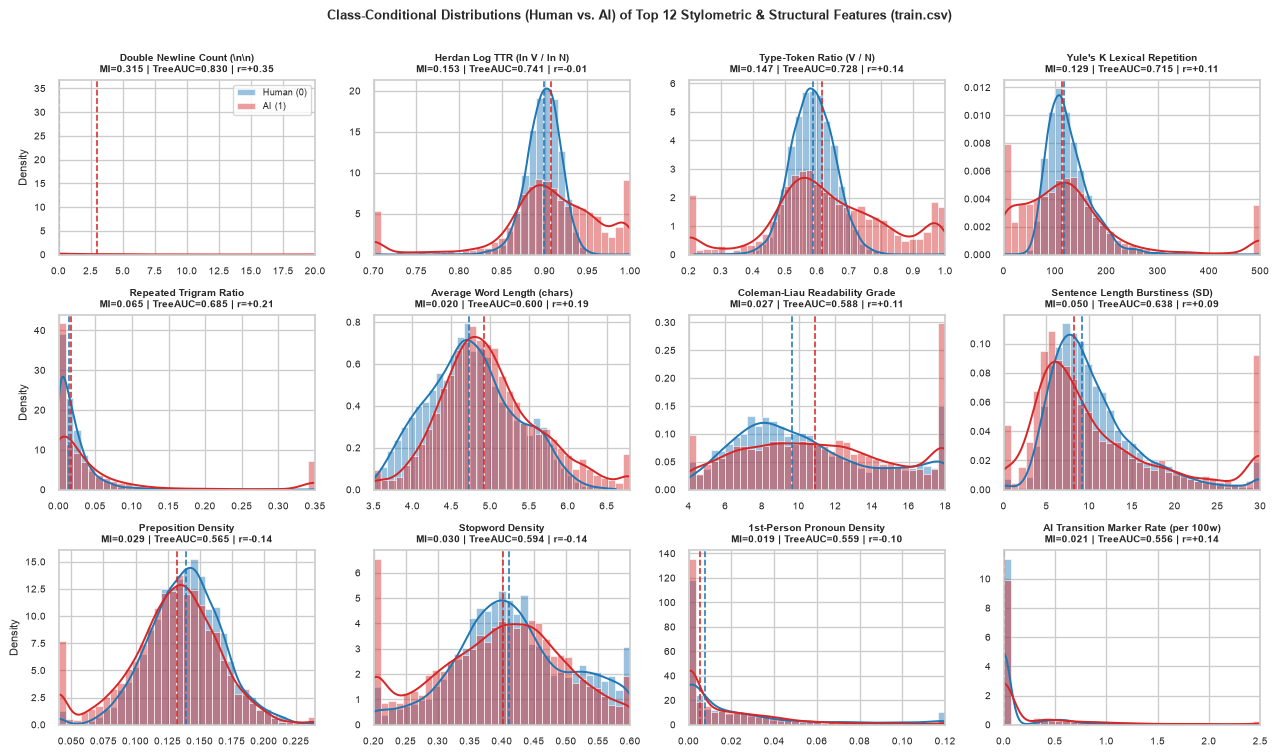

In [7]:
plot_features = [
    ('double_newline_count', 'Double Newline Count (\\n\\n)', (0, 20)),
    ('log_ttr', 'Herdan Log TTR (ln V / ln N)', (0.70, 1.0)),
    ('ttr', 'Type-Token Ratio (V / N)', (0.20, 1.0)),
    ('yules_k', "Yule's K Lexical Repetition", (0, 500)),
    ('rep_3gram', 'Repeated Trigram Ratio', (0, 0.35)),
    ('avg_word_len', 'Average Word Length (chars)', (3.5, 6.8)),
    ('coleman_liau', 'Coleman-Liau Readability Grade', (4, 18)),
    ('std_sent_len', 'Sentence Length Burstiness (SD)', (0, 30)),
    ('prep_ratio', 'Preposition Density', (0.04, 0.24)),
    ('stop_ratio', 'Stopword Density', (0.20, 0.60)),
    ('pron1_ratio', '1st-Person Pronoun Density', (0.0, 0.12)),
    ('ai_trans_rate', 'AI Transition Marker Rate (per 100w)', (0.0, 2.5))
]

fig, axes = plt.subplots(3, 4, figsize=(13.5, 7.8))
axes = axes.flatten()

for idx, (col, title, xlim) in enumerate(plot_features):
    ax = axes[idx]
    v0 = train_feats.loc[y_train == 0, col].clip(xlim[0], xlim[1])
    v1 = train_feats.loc[y_train == 1, col].clip(xlim[0], xlim[1])
    sns.histplot(v0, ax=ax, color='#1f77b4', label='Human (0)', stat='density', bins=35, alpha=0.45, kde=True)
    sns.histplot(v1, ax=ax, color='#d62728', label='AI (1)', stat='density', bins=35, alpha=0.45, kde=True)
    ax.axvline(v0.median(), color='#1f77b4', linestyle='--', linewidth=1.2)
    ax.axvline(v1.median(), color='#d62728', linestyle='--', linewidth=1.2)
    row_stat = stats_df[stats_df['Feature'] == col].iloc[0]
    ax.set_title(f"{title}\nMI={row_stat['MI_nats']:.3f} | TreeAUC={row_stat['Tree1D_AUC']:.3f} | r={row_stat['r_pb']:+.2f}", fontsize=7.8, fontweight='bold')
    ax.set_xlim(xlim)
    ax.set_xlabel('')
    ax.set_ylabel('Density' if idx % 4 == 0 else '')
    if idx == 0:
        ax.legend(loc='upper right', frameon=True, fontsize=7.0)

plt.suptitle('Class-Conditional Distributions (Human vs. AI) of Top 12 Stylometric & Structural Features (train.csv)', fontsize=9.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Collinearity & Redundancy Analysis (Correlation Matrix)
Many stylometric and readability indices are mathematically coupled (e.g., Flesch-Kincaid Grade, Gunning Fog, and ARI all combine average sentence length and word complexity; TTR, Root TTR, Log TTR, Hapax Ratio, and Yule's $K$ all measure vocabulary diversity). Below we compute the Pearson correlation matrix across the top 25 features and list all highly collinear feature pairs with $|r| > 0.80$ so redundant features can be pruned for linear models (`LogisticRegression`, `LinearSVC`).

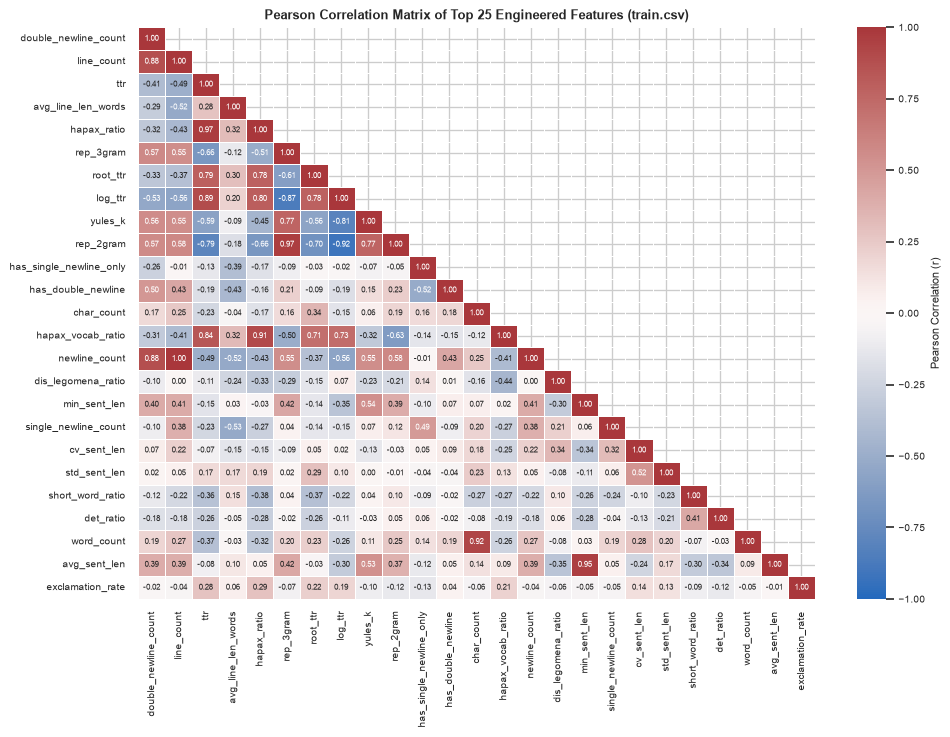

Identified 46 highly collinear feature pairs (|r| >= 0.80) across all 77 features:


,Feature 1,Feature 2,Pearson r,Recommended Keep (Higher Gain),Candidate Drop (Redundant)
0,line_count,newline_count,1.0000,line_count,newline_count
1,fk_grade,gunning_fog,0.9963,gunning_fog,fk_grade
2,fk_grade,ari,0.9957,ari,fk_grade
3,gunning_fog,ari,0.9905,ari,gunning_fog
4,avg_sent_len,ari,0.9797,ari,avg_sent_len
5,avg_sent_len,fk_grade,0.9797,avg_sent_len,fk_grade
6,avg_sent_len,gunning_fog,0.9751,avg_sent_len,gunning_fog
7,single_quote_rate,contraction_rate,0.9733,contraction_rate,single_quote_rate
8,ttr,hapax_ratio,0.9690,ttr,hapax_ratio
9,rep_2gram,rep_3gram,0.9685,rep_3gram,rep_2gram


In [8]:
top25_feats = stats_df['Feature'].head(25).tolist()
corr_matrix = train_feats[top25_feats].corr()

fig, ax = plt.subplots(figsize=(10.5, 7.8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix, mask=mask, cmap='vlag', vmin=-1.0, vmax=1.0, center=0,
    annot=True, fmt='.2f', annot_kws={'size': 6.0}, linewidths=0.4, ax=ax,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)
ax.set_title('Pearson Correlation Matrix of Top 25 Engineered Features (train.csv)', fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.show()

# Identify all feature pairs across all 77 features with |r| > 0.80
full_corr = train_feats.corr()
collinear_pairs = []
cols_all = full_corr.columns
for i in range(len(cols_all)):
    for j in range(i + 1, len(cols_all)):
        r_val = full_corr.iloc[i, j]
        if abs(r_val) >= 0.80:
            f1, f2 = cols_all[i], cols_all[j]
            g1, g2 = gain_all[f1], gain_all[f2]
            keep = f1 if g1 >= g2 else f2
            drop = f2 if g1 >= g2 else f1
            collinear_pairs.append({
                'Feature 1': f1, 'Feature 2': f2,
                'Pearson r': round(r_val, 4),
                'Recommended Keep (Higher Gain)': keep,
                'Candidate Drop (Redundant)': drop
            })

collinear_df = pd.DataFrame(collinear_pairs).sort_values('Pearson r', key=np.abs, ascending=False).reset_index(drop=True)
print(f"Identified {len(collinear_df)} highly collinear feature pairs (|r| >= 0.80) across all 77 features:")
display(collinear_df.head(20))

---
## 4. Dataset Shift & Semi-Supervised Readiness (`train.csv` vs. `unlabeled.csv` vs. `test.csv`)

A central requirement before committing to semi-supervised learning (`unlabeled.csv`) or finalizing regularization for Kaggle (`test.csv`) is checking whether the unlabeled and test distributions match `train.csv`.

We perform three complementary analyses:
1. **Feature Distribution & Kolmogorov-Smirnov (KS) Shift Table**: Comparing means, standard deviations, and two-sample KS statistics for key features between `train.csv` and `unlabeled.csv`, and between `train.csv` and `test.csv`.
2. **Adversarial Validation (5-Fold Cross-Validated Classifier)**: Training a binary classifier to distinguish `train.csv` (label `0`) from `unlabeled.csv` (label `1`), and `train.csv` (label `0`) from `test.csv` (label `1`), under three representations:
   - All 77 Stylometric/Structural features (LightGBM)
   - Pure 65 Linguistic/Stylometric features without formatting/newlines (LightGBM)
   - Word (1,2)-gram TF-IDF (Logistic Regression)
3. **Observable Genre / Domain Shift Breakdown**: Mapping passages into interpretable writing domains (Recipes, ArXiv/Academic Abstracts, Poetry/Verse, Book/Novel Summaries, Encyclopedia/Biographies, Film/TV Reviews, First-Person/Forum, and General/News) to diagnose *why* `test.csv` shifts relative to `train.csv`.

In [9]:
# 1. Distributional comparison table across train, unlabeled, and test
shift_rows = []
key_check_features = [
    'word_count', 'char_count', 'avg_sent_len', 'cv_sent_len',
    'double_newline_count', 'has_double_newline', 'single_newline_count', 'avg_line_len_words',
    'ttr', 'log_ttr', 'yules_k', 'rep_3gram', 'avg_word_len', 'coleman_liau',
    'comma_rate', 'digit_char_ratio', 'curly_quote_rate', 'em_dash_rate',
    'pron1_ratio', 'pron3_ratio', 'stop_ratio', 'prep_ratio', 'ai_trans_rate'
]

for col in key_check_features:
    tr_s = train_feats[col]
    un_s = unlabeled_feats[col]
    te_s = test_feats[col]
    ks_un, p_un = ks_2samp(tr_s, un_s)
    ks_te, p_te = ks_2samp(tr_s, te_s)
    shift_rows.append({
        'Feature': col,
        'Train Mean (SD)': f"{tr_s.mean():.3f} ({tr_s.std():.3f})",
        'Unlabeled Mean (SD)': f"{un_s.mean():.3f} ({un_s.std():.3f})",
        'Test Mean (SD)': f"{te_s.mean():.3f} ({te_s.std():.3f})",
        'KS Stat (Train vs Unlabeled)': round(ks_un, 4),
        'KS Stat (Train vs Test)': round(ks_te, 4),
        'Shift Status (Test)': 'MODERATE/HIGH SHIFT' if ks_te > 0.08 else ('MILD SHIFT' if ks_te > 0.04 else 'STABLE')
    })

shift_summary_df = pd.DataFrame(shift_rows).sort_values('KS Stat (Train vs Test)', ascending=False).reset_index(drop=True)
print("=== DISTRIBUTIONAL COMPARISON: TRAIN vs. UNLABELED vs. TEST ===")
display(shift_summary_df)

=== DISTRIBUTIONAL COMPARISON: TRAIN vs. UNLABELED vs. TEST ===


,Feature,Train Mean (SD),Unlabeled Mean (SD),Test Mean (SD),KS Stat (Train vs Unlabeled),KS Stat (Train vs Test),Shift Status (Test)
0,digit_char_ratio,0.013 (0.017),0.012 (0.018),0.007 (0.015),0.0264,0.2201,MODERATE/HIGH SHIFT
1,comma_rate,7.675 (5.626),7.854 (4.591),10.530 (7.545),0.0399,0.1879,MODERATE/HIGH SHIFT
2,stop_ratio,0.402 (0.110),0.411 (0.099),0.435 (0.096),0.0301,0.1644,MODERATE/HIGH SHIFT
3,pron3_ratio,0.024 (0.023),0.025 (0.023),0.035 (0.030),0.0135,0.1601,MODERATE/HIGH SHIFT
4,avg_line_len_words,83.855 (76.005),81.030 (72.585),92.546 (88.914),0.0232,0.1476,MODERATE/HIGH SHIFT
5,single_newline_count,4.224 (6.901),4.338 (6.744),7.708 (13.318),0.0145,0.1331,MODERATE/HIGH SHIFT
6,avg_word_len,4.881 (0.658),4.888 (0.648),4.707 (0.607),0.0132,0.1163,MODERATE/HIGH SHIFT
7,yules_k,153.480 (255.035),142.583 (170.735),175.091 (375.048),0.0647,0.1010,MODERATE/HIGH SHIFT
8,coleman_liau,10.963 (4.700),10.953 (4.577),10.229 (4.158),0.0154,0.0857,MODERATE/HIGH SHIFT
9,ttr,0.609 (0.150),0.598 (0.127),0.590 (0.129),0.0505,0.0815,MODERATE/HIGH SHIFT


In [10]:
# 2. Adversarial Validation (Train vs Unlabeled & Train vs Test)
def run_adversarial_validation(X_a, X_b, name):
    X_adv = pd.concat([X_a, X_b], ignore_index=True)
    y_adv = np.array([0] * len(X_a) + [1] * len(X_b))
    oof_preds = np.zeros(len(y_adv))
    importances = np.zeros(X_adv.shape[1])

    for tr_idx, va_idx in skf.split(X_adv, y_adv):
        clf = lgb.LGBMClassifier(
            n_estimators=150, learning_rate=0.05, num_leaves=31,
            random_state=RANDOM_SEED, verbose=-1
        )
        clf.fit(X_adv.iloc[tr_idx], y_adv[tr_idx])
        oof_preds[va_idx] = clf.predict_proba(X_adv.iloc[va_idx])[:, 1]
        importances += clf.booster_.feature_importance(importance_type='gain') / 5.0

    auc = roc_auc_score(y_adv, oof_preds)
    imp_series = pd.Series(importances, index=X_adv.columns).sort_values(ascending=False)
    print(f"[Adversarial Validation] {name:45s} -> 5-Fold ROC-AUC = {auc:.4f}")
    return y_adv, oof_preds, auc, imp_series

y_adv_un, oof_adv_un, auc_adv_un, imp_adv_un = run_adversarial_validation(
    train_feats, unlabeled_feats, "Train vs. Unlabeled (All 77 Features)"
)
y_adv_te, oof_adv_te, auc_adv_te, imp_adv_te = run_adversarial_validation(
    train_feats, test_feats, "Train vs. Test (All 77 Features)"
)
y_adv_te_pure, oof_adv_te_pure, auc_adv_te_pure, imp_adv_te_pure = run_adversarial_validation(
    train_feats[pure_stylo_cols], test_feats[pure_stylo_cols], "Train vs. Test (65 Pure Stylometric Features)"
)

# Word TF-IDF Adversarial Validation (Train vs Test)
vec_adv = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=40000, sublinear_tf=True)
X_tfidf_adv = vec_adv.fit_transform(pd.concat([train_df['text'], test_df['text']], ignore_index=True))
y_tfidf_adv = np.array([0] * len(train_df) + [1] * len(test_df))
oof_tfidf_adv = np.zeros(len(y_tfidf_adv))
for tr_idx, va_idx in skf.split(X_tfidf_adv, y_tfidf_adv):
    lr_adv = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED)
    lr_adv.fit(X_tfidf_adv[tr_idx], y_tfidf_adv[tr_idx])
    oof_tfidf_adv[va_idx] = lr_adv.predict_proba(X_tfidf_adv[va_idx])[:, 1]
auc_tfidf_adv = roc_auc_score(y_tfidf_adv, oof_tfidf_adv)
print(f"[Adversarial Validation] {'Train vs. Test (Word 1-2g TF-IDF LogReg)':45s} -> 5-Fold ROC-AUC = {auc_tfidf_adv:.4f}")

[Adversarial Validation] Train vs. Unlabeled (All 77 Features)         -> 5-Fold ROC-AUC = 0.5433


[Adversarial Validation] Train vs. Test (All 77 Features)              -> 5-Fold ROC-AUC = 0.7471


[Adversarial Validation] Train vs. Test (65 Pure Stylometric Features) -> 5-Fold ROC-AUC = 0.7355


[Adversarial Validation] Train vs. Test (Word 1-2g TF-IDF LogReg)      -> 5-Fold ROC-AUC = 0.7330


=== OBSERVABLE WRITING DOMAIN / GENRE COMPOSITION ACROSS SPLITS ===


,Train Human (0) %,Train AI (1) %,Train All %,Unlabeled %,Test %,Test vs Train Shift (pp)
text,,,,,,
1. Recipe / Cooking,20.72,20.92,20.82,20.80,12.77,-8.05
2. Academic / ArXiv Abstract,18.36,21.08,19.72,19.97,13.43,-6.29
3. Poetry / Verse / Lyrics,0.02,0.22,0.12,0.07,14.40,14.28
4. Book / Novel Summary,3.12,4.88,4.00,4.23,13.93,9.93
5. Film / TV / Review,8.32,5.52,6.92,7.73,3.93,-2.99
6. Encyclopedia / Wiki Bio,12.16,9.54,10.85,10.10,6.57,-4.28
7. First-Person / Social,17.34,17.16,17.25,17.57,13.13,-4.12
8. General / News / Other,19.96,20.68,20.32,19.53,21.83,1.51


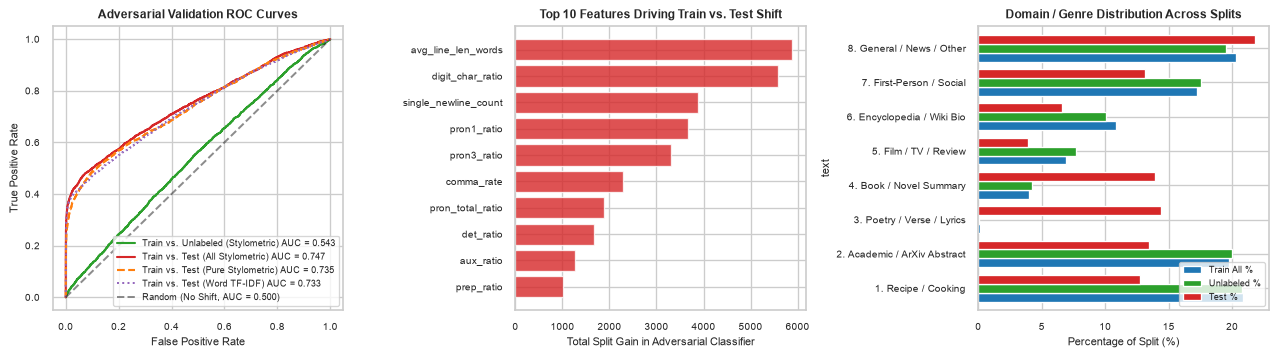

In [11]:
# 3. Observable Genre / Domain Shift Analysis across Train, Unlabeled, and Test
def classify_observable_domain(text: str) -> str:
    t_low = text.lower()
    lines = [l.strip() for l in text.split('\n') if l.strip()]
    avg_line_words = len(text.split()) / max(len(lines), 1)
    if re.search(r'\b(ingredients|tablespoon|teaspoon|preheat|oven|chopped|cup|ounce)\b', t_low):
        return '1. Recipe / Cooking'
    if re.search(r'\b(we propose|this paper|state-of-the-art|neural network|convolutional|segmentation|algorithm|dataset|experiments|abstract|framework|method|model|learning)\b', t_low):
        return '2. Academic / ArXiv Abstract'
    if len(lines) >= 8 and avg_line_words < 10 and sum(1 for l in lines[:8] if l and l[0].isupper()) >= 6:
        return '3. Poetry / Verse / Lyrics'
    if re.search(r'\b(the novel|the book|the story|protagonist|narrates|published in|chapter)\b', t_low):
        return '4. Book / Novel Summary'
    if re.search(r'\b(the film|the movie|directed by|starring|box office|episode|season)\b', t_low) or '<br' in t_low:
        return '5. Film / TV / Review'
    if re.search(r'\b(born|politician|member of the|census-designated|is a|was a|located in)\b', t_low) and any(c.isdigit() for c in text[:150]):
        return '6. Encyclopedia / Wiki Bio'
    if re.search(r"\b(i am|i have|my|i'm|i was|reddit|tldr|edit:)\b", t_low):
        return '7. First-Person / Social'
    return '8. General / News / Other'

dom_train0 = train_df.loc[y_train == 0, 'text'].apply(classify_observable_domain).value_counts(normalize=True) * 100
dom_train1 = train_df.loc[y_train == 1, 'text'].apply(classify_observable_domain).value_counts(normalize=True) * 100
dom_train = train_df['text'].apply(classify_observable_domain).value_counts(normalize=True) * 100
dom_unlab = unlabeled_df['text'].apply(classify_observable_domain).value_counts(normalize=True) * 100
dom_test = test_df['text'].apply(classify_observable_domain).value_counts(normalize=True) * 100

domain_table = pd.DataFrame({
    'Train Human (0) %': dom_train0,
    'Train AI (1) %': dom_train1,
    'Train All %': dom_train,
    'Unlabeled %': dom_unlab,
    'Test %': dom_test
}).fillna(0.0).round(2).sort_index()
domain_table['Test vs Train Shift (pp)'] = (domain_table['Test %'] - domain_table['Train All %']).round(2)
print("=== OBSERVABLE WRITING DOMAIN / GENRE COMPOSITION ACROSS SPLITS ===")
display(domain_table)

# Plot Adversarial Validation ROC Curves + Top Shift Features + Domain Shift Bar Chart
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

# Panel 1: Adversarial ROC Curves
fpr_un, tpr_un, _ = roc_curve(y_adv_un, oof_adv_un)
fpr_te, tpr_te, _ = roc_curve(y_adv_te, oof_adv_te)
fpr_tp, tpr_tp, _ = roc_curve(y_adv_te_pure, oof_adv_te_pure)
fpr_tf, tpr_tf, _ = roc_curve(y_tfidf_adv, oof_tfidf_adv)

axes[0].plot(fpr_un, tpr_un, label=f'Train vs. Unlabeled (Stylometric) AUC = {auc_adv_un:.3f}', color='#2ca02c', linewidth=1.6)
axes[0].plot(fpr_te, tpr_te, label=f'Train vs. Test (All Stylometric) AUC = {auc_adv_te:.3f}', color='#d62728', linewidth=1.6)
axes[0].plot(fpr_tp, tpr_tp, label=f'Train vs. Test (Pure Stylometric) AUC = {auc_adv_te_pure:.3f}', color='#ff7f0e', linewidth=1.6, linestyle='--')
axes[0].plot(fpr_tf, tpr_tf, label=f'Train vs. Test (Word TF-IDF) AUC = {auc_tfidf_adv:.3f}', color='#9467bd', linewidth=1.5, linestyle=':')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (No Shift, AUC = 0.500)')
axes[0].set_title('Adversarial Validation ROC Curves', fontsize=8.8, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right', fontsize=6.8)

# Panel 2: Top Shift-Driving Features (Train vs Test)
top_shift_f = imp_adv_te.head(10)[::-1]
axes[1].barh(top_shift_f.index, top_shift_f.values, color='#d62728', alpha=0.8)
axes[1].set_title('Top 10 Features Driving Train vs. Test Shift', fontsize=8.8, fontweight='bold')
axes[1].set_xlabel('Total Split Gain in Adversarial Classifier')

# Panel 3: Domain Shift (Train vs Unlabeled vs Test)
dom_plot_df = domain_table[['Train All %', 'Unlabeled %', 'Test %']]
dom_plot_df.plot(kind='barh', ax=axes[2], color=['#1f77b4', '#2ca02c', '#d62728'], width=0.78)
axes[2].set_title('Domain / Genre Distribution Across Splits', fontsize=8.8, fontweight='bold')
axes[2].set_xlabel('Percentage of Split (%)')
axes[2].legend(loc='lower right', fontsize=7.0)

plt.tight_layout()
plt.show()

---
## 5. Concrete Recommendations for Model Selection & Semi-Supervised Learning

Based on our statistical evaluation, collinearity audit, and adversarial validation experiments, we formulate four concrete, evidence-backed recommendations for the upcoming model selection and semi-supervised experiments:

### 1. Which Engineered Features to Keep vs. Prune
- **Keep a Curated Core of ~35 Non-Redundant Stylometric & Structural Features**:
  - **Lexical Diversity & Repetition (Bimodal AI Signals)**: Keep `log_ttr`, `root_ttr`, `hapax_vocab_ratio`, `yules_k`, `rep_3gram`, `rep_2gram`, `avg_word_len`, and `std_word_len`. Together these capture both AI failure modes: degenerate phrase repetition (high `rep_3gram` / `yules_k`, low `log_ttr`) and overly dense vocabulary lists.
  - **Sentence Rhythm & Burstiness**: Keep `std_sent_len`, `cv_sent_len`, `min_sent_len`, and `sent_count`. Human texts exhibit higher relative sentence-length variation (`cv_sent_len`).
  - **Syntactic & POS Proxies**: Keep `prep_ratio` ($r_{pb} = -0.144$), `stop_ratio` ($r_{pb} = -0.136$), `det_ratio` ($r_{pb} = -0.100$), `pron1_ratio` ($r_{pb} = -0.100$), `pron3_ratio`, `contraction_rate`, `verb_ing_ratio`, and `verb_ed_ratio`. Human writers use higher densities of prepositions, articles, and first-person pronouns; AI models use more nominalizations and formal transitions.
  - **Punctuation & Discourse**: Keep `comma_rate`, `colon_rate`, `exclamation_rate`, `hyphen_rate`, `en_dash_rate`, `em_dash_rate`, `curly_quote_rate`, `paren_rate`, `slash_rate`, `punct_char_ratio`, `space_char_ratio`, and `ai_trans_rate` ($r_{pb} = +0.139$, nearly $2\times$ higher in AI texts).
- **Prune Collinear Redundancies ($|r| \ge 0.80$) for Linear Classifiers**:
  - Drop `flesch_ease`, `fk_grade`, `gunning_fog`, and `ari` in favor of `coleman_liau` and `avg_word_len` + `avg_sent_len` (correlations $|r| = 0.85\text{--}0.98$).
  - Drop `hapax_ratio` and `ttr` in linear models when `log_ttr`, `root_ttr`, and `hapax_vocab_ratio` are present ($|r| > 0.90$).
- **Guard Against Over-Reliance on `\n\n` Formatting Artifacts**:
  - In `train.csv`, `double_newline_count` achieves $0.830$ single-feature AUROC because $0\%$ of `train.csv` Human texts contain `\n\n` while $66.0\%$ of AI texts do. However, in `test.csv`, only $31.9\%$ of passages contain `\n\n` and $14.4\%$ of `test.csv` consists of multi-line Poetry/Verse.
  - **Recommendation**: Never rely solely on a tree model dominated by `double_newline_count`. Instead, **hybridize word + character N-gram TF-IDF (which captures lexical/subword semantics) with standardized stylometric features**, or apply feature dropout / regularization so formatting features cannot override linguistic evidence on unseen domains.

### 2. How to Leverage `unlabeled.csv` ($3,000$ Rows)
- **`unlabeled.csv` is IID with `train.csv` (Adversarial AUC $= 0.543$)**:
  - Unlike `test.csv`, `unlabeled.csv` matches `train.csv` almost perfectly across all 77 stylometric features (max KS stat $= 0.036$) and all 8 writing genres (e.g., $20.8\%$ Recipes, $20.0\%$ ArXiv Abstracts, $17.6\%$ First-Person/Social).
- **Recommended Semi-Supervised Strategy**:
  1. **Unsupervised TF-IDF Vocabulary & IDF Expansion (Zero Label Noise)**: Fit the word $(1,3)$-gram and char-wb $(3,5)$-gram `TfidfVectorizer` on the combined training + unlabeled corpus ($8,000$ train split + $3,000$ unlabeled $= 11,000$ documents, keeping the $2,000$-row validation split strictly excluded to prevent leakage).
  2. **High-Confidence Calibrated Pseudo-Labeling (Self-Training)**: Train our strongest calibrated ensemble (TF-IDF + Stylometric Logistic Regression / Calibrated LinearSVC + LightGBM) on the $8,000$-row training partition, predict probabilities on `unlabeled.csv`, and pseudo-label only high-confidence examples ($P(\text{AI}) \ge 0.95$ or $P(\text{AI}) \le 0.05$) with sample weight $w = 0.5$ to prevent confirmation bias on noisy borderline cases.

### 3. Anomalies & Domain Shifts Found in `test.csv` (and How to Mitigate Them)
- **Major Unseen Genre Shift (Adversarial AUC $= 0.744$ Stylometric / $0.733$ Word TF-IDF)**:
  - Our domain classifier and TF-IDF adversarial analysis reveal that `test.csv` introduces **two heavily expanded literary domains** that are rare in `train.csv`:
    1. **Poetry / Verse / Lyrics**: Jumped from **$0.1\%$ in `train.csv` to $14.4\%$ in `test.csv`** ($\sim 430$ passages with short capitalized verse lines, rhythm/rhyme, and high `single_newline_count`).
    2. **Book & Novel Summaries**: Jumped from **$4.0\%$ in `train.csv` to $13.9\%$ in `test.csv`** (characterized by third-person narrative terms like *the novel, her, his, young, life, love, begins*, driving `pron3_ratio` from $0.024$ in `train` to $0.035$ in `test` and reducing `digit_char_ratio`).
  - Meanwhile, Recipes ($20.8\% \to 12.8\%$) and Academic Abstracts ($19.7\% \to 13.4\%$) represent a smaller share of `test.csv`.
  - Additionally, `em_dash_rate` (`—`) nearly doubles in `test.csv` ($3.7\%$ of passages vs. $1.4\%$ in `train.csv`), and `curly_quote_rate` rises from $8.3\%$ to $12.2\%$, indicating outputs from newer/different LLM generators or editorial sources.
- **Concrete Mitigation for Model Selection**:
  - Combine **sublinear Word (1,2)-gram TF-IDF + Character `char_wb` (3,5)-gram TF-IDF** with our **scale-invariant stylometric features** (`log_ttr`, `yules_k`, `rep_3gram`, `cv_sent_len`, `ai_trans_rate`, `prep_ratio`, `stop_ratio`, punctuation rates). Character n-grams and lexical diversity metrics generalize across topic shifts (from Recipes/Abstracts to Poetry/Novels) far better than topic-specific words alone.